11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

=== MNIST ===
Train: (60000, 28, 28) Test: (10000, 28, 28)
dtype: uint8 | pixel range: 0 - 255
Mean: 33.32  Std: 78.57


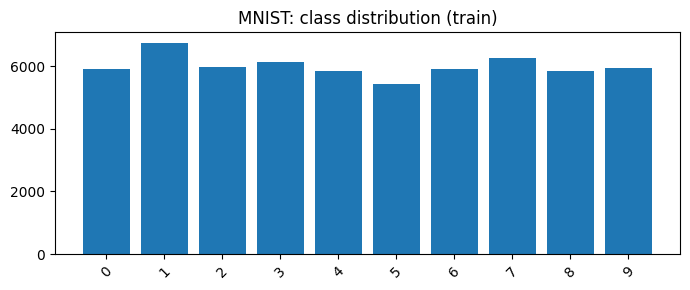

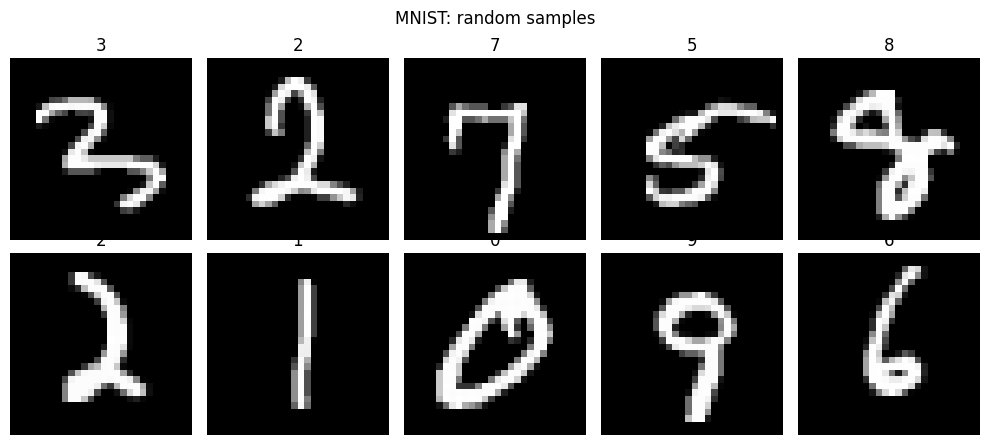

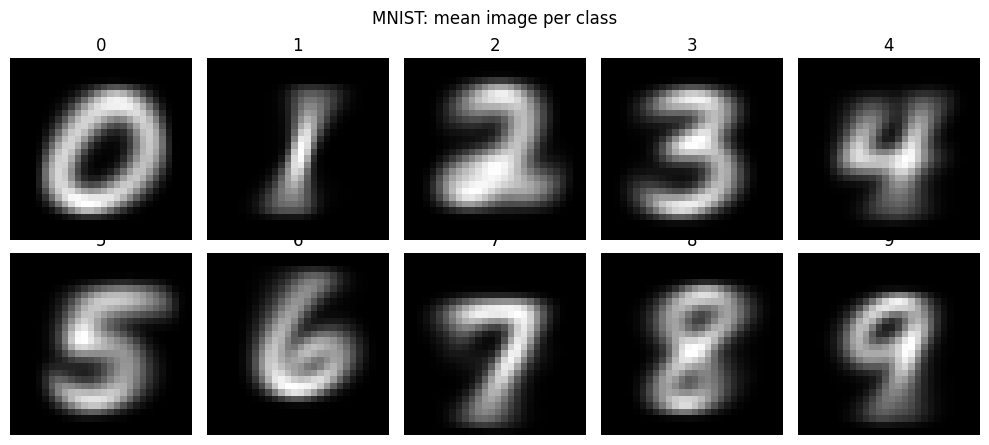

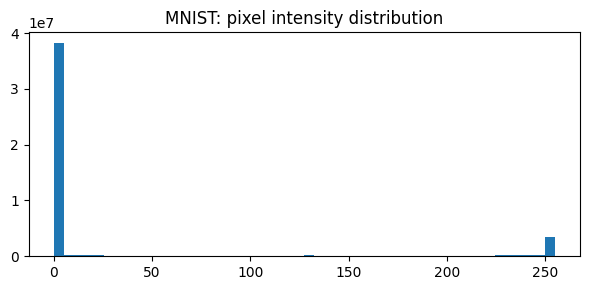

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

=== Fashion-MNIST ===
Train: (60000, 28, 28) Test: (10000, 28, 28)
dtype: uint8 | pixel range: 0 - 255
Mean: 72.94  Std: 90.02


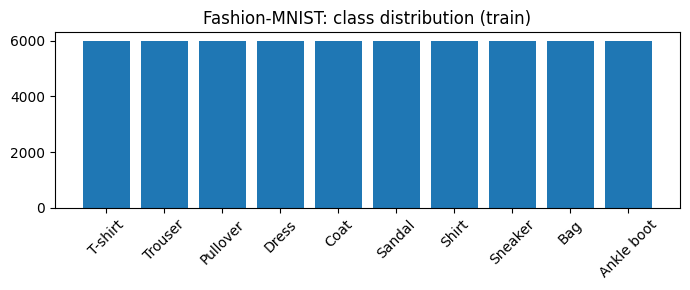

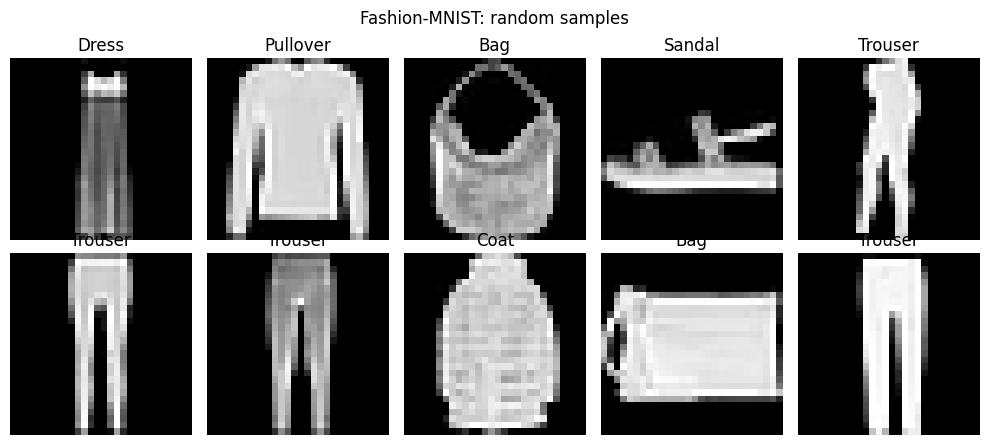

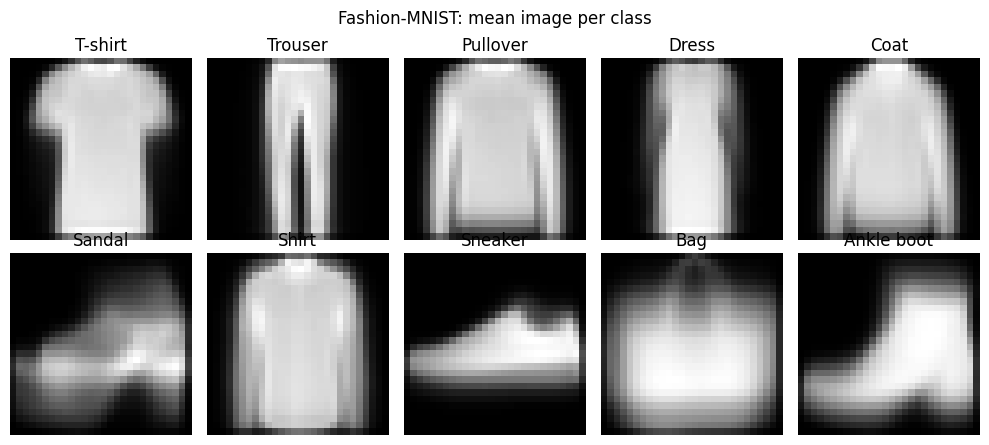

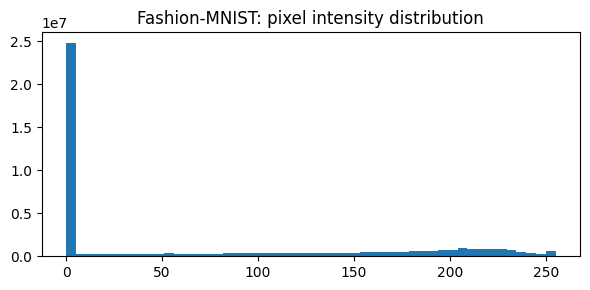

 62554112/170498071 ━━━━━━━━━━━━━━━━━━━━ 18:14 10us/step

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist, fashion_mnist, cifar10

datasets = {
    "MNIST": (mnist, ["0","1","2","3","4","5","6","7","8","9"]),
    "Fashion-MNIST": (fashion_mnist, ["T-shirt","Trouser","Pullover","Dress","Coat",
                                      "Sandal","Shirt","Sneaker","Bag","Ankle boot"]),
    "CIFAR-10": (cifar10, ["airplane","automobile","bird","cat","deer",
                           "dog","frog","horse","ship","truck"]),
}

for name, (ds, classes) in datasets.items():
    (X_train, y_train), (X_test, y_test) = ds.load_data()
    y_train, y_test = y_train.flatten(), y_test.flatten()

    # 1. Basic info
    print(f"\n=== {name} ===")
    print("Train:", X_train.shape, "Test:", X_test.shape)
    print("dtype:", X_train.dtype, "| pixel range:", X_train.min(), "-", X_train.max())
    print("Mean: %.2f  Std: %.2f" % (X_train.mean(), X_train.std()))

    # 2. Class distribution
    counts = np.bincount(y_train)
    plt.figure(figsize=(7, 3))
    plt.bar(classes, counts)
    plt.xticks(rotation=45); plt.title(f"{name}: class distribution (train)")
    plt.tight_layout(); plt.savefig(f"{name}_class_dist.png"); plt.show()

    # 3. Sample images (one row of 10 random samples per run)
    fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))
    for ax, i in zip(axes.ravel(), np.random.choice(len(X_train), 10, replace=False)):
        ax.imshow(X_train[i], cmap="gray" if X_train.ndim == 3 else None)
        ax.set_title(classes[y_train[i]]); ax.axis("off")
    plt.suptitle(f"{name}: random samples"); plt.tight_layout()
    plt.savefig(f"{name}_samples.png"); plt.show()

    # 4. Mean image per class
    fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))
    for c, ax in enumerate(axes.ravel()):
        mean_img = X_train[y_train == c].mean(axis=0).astype("uint8")
        ax.imshow(mean_img, cmap="gray" if X_train.ndim == 3 else None)
        ax.set_title(classes[c]); ax.axis("off")
    plt.suptitle(f"{name}: mean image per class"); plt.tight_layout()
    plt.savefig(f"{name}_mean_images.png"); plt.show()

    # 5. Pixel intensity histogram
    plt.figure(figsize=(6, 3))
    plt.hist(X_train.ravel(), bins=50)
    plt.title(f"{name}: pixel intensity distribution"); plt.tight_layout()
    plt.savefig(f"{name}_pixel_hist.png"); plt.show()